# 03 - Feature Engineering and Planar Projection

**Title**: `03_features_and_projection.ipynb`  
**Purpose**: Add temporal features, project geographic coordinates onto a local meter grid (x_m, y_m), validate projection fidelity against geodesic haversine distance, perform round-trip inversion and perturbation checks, and audit feature distributions.  
**Inputs**: `data/processed/brooklyn_stage1.csv.gz`, `data/processed/projection.json`, `data/processed/brooklyn_stage2.csv.gz`  
**Outputs**: Projected local coordinates, feature audit statistics, diagnostic plots (`report/figures/03_brooklyn_scatter.png`, `report/figures/03_complaints_by_hour.png`, `report/figures/03_time_to_close_hist.png`)  
**Runtime**: ~15-20 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
from src.nbutils import Checker, md
RUN_HEAVY = False
RUN_API = False

In [2]:
import pandas as pd
import numpy as np
from src.preprocessing.features import (
    add_time_features, project, unproject, add_projection,
    load_projection_constants, haversine_distance
)

s1_path = ROOT / "data" / "processed" / "brooklyn_stage1.csv.gz"
str_cols = ["unique_key", "resolution_id", "status", "channel", "location_type", "complaint_type", "descriptor", "group", "borough", "incident_address", "address_norm"]
df = pd.read_csv(s1_path, dtype={c: str for c in str_cols})
df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
df["closed_date"] = pd.to_datetime(df["closed_date"], errors="coerce")
df["latitude"] = df["latitude"].astype(float)
df["longitude"] = df["longitude"].astype(float)

lat0_recomputed = round(float(df["latitude"].mean()), 6)
lon0_recomputed = round(float(df["longitude"].mean()), 6)

proj_json_path = ROOT / "data" / "processed" / "projection.json"
lat0_saved, lon0_saved = load_projection_constants(proj_json_path)

print(f"Recomputed Origin : lat0 = {lat0_recomputed:.6f}, lon0 = {lon0_recomputed:.6f}")
print(f"Saved JSON Origin : lat0 = {lat0_saved:.6f}, lon0 = {lon0_saved:.6f}")
print(f"Match: lat0 diff = {abs(lat0_recomputed - lat0_saved):.2e}, lon0 diff = {abs(lon0_recomputed - lon0_saved):.2e}")

Recomputed Origin : lat0 = 40.661641, lon0 = -73.952455
Saved JSON Origin : lat0 = 40.661641, lon0 = -73.952455
Match: lat0 diff = 0.00e+00, lon0 diff = 0.00e+00


In [3]:
df = add_time_features(df)
df = add_projection(df, lat0_saved, lon0_saved)

print(f"Added features to {len(df):,} rows.")
print(df[["unique_key", "hour", "weekday", "month", "is_midnight_timestamp", "time_to_close_h", "x_m", "y_m"]].head(5).to_string(index=False))

Added features to 236,507 rows.
unique_key  hour  weekday  month  is_midnight_timestamp  time_to_close_h          x_m         y_m
  70966017    23        5     10                  False        41.983889  1838.239302 1311.437119
  70958439    23        5     10                  False         0.553889  5088.546594 2039.374344
  70956995    23        5     10                  False         0.605556   695.626585 2561.681625
  70966005    23        5     10                  False         0.776111 -3664.117424 3039.820280
  70956966    23        5     10                  False         0.911667  -167.481207 1542.123937


In [4]:
rng = np.random.default_rng(42)
n_rows = len(df)
lats, lons = df["latitude"].values, df["longitude"].values
xs, ys = df["x_m"].values, df["y_m"].values

pairs_idx1, pairs_idx2 = [], []
while len(pairs_idx1) < 2000:
    i1 = rng.integers(0, n_rows, size=3000)
    i2 = rng.integers(0, n_rows, size=3000)
    valid = i1 != i2
    i1, i2 = i1[valid], i2[valid]
    h_dists = haversine_distance(lats[i1], lons[i1], lats[i2], lons[i2])
    far = h_dists > 500.0
    pairs_idx1.extend(i1[far])
    pairs_idx2.extend(i2[far])

idx1 = np.array(pairs_idx1[:2000])
idx2 = np.array(pairs_idx2[:2000])

h_true = haversine_distance(lats[idx1], lons[idx1], lats[idx2], lons[idx2])
e_proj = np.sqrt((xs[idx1] - xs[idx2])**2 + (ys[idx1] - ys[idx2])**2)
rel_err = np.abs(e_proj - h_true) / h_true

# Wrong formula: degrees passed to cos
x_wrong = (lons - lon0_saved) * 111320.0 * np.cos(lat0_saved)
e_wrong = np.sqrt((x_wrong[idx1] - x_wrong[idx2])**2 + (ys[idx1] - ys[idx2])**2)
rel_err_wrong = np.abs(e_wrong - h_true) / h_true

mean_rel_err = float(rel_err.mean())
median_rel_err = float(np.median(rel_err))
p95_rel_err = float(np.percentile(rel_err, 95))
max_rel_err = float(rel_err.max())
mean_rel_err_wrong = float(rel_err_wrong.mean())

print("=== Projection Accuracy on 2,000 Distant Pairs (>500m) ===")
print(f"Correct Formula (Mean Relative Error)  : {mean_rel_err:.6f} ({mean_rel_err*100:.4f}%)")
print(f"Correct Formula (Median Relative Error): {median_rel_err:.6f} ({median_rel_err*100:.4f}%)")
print(f"Correct Formula (95th Percentile)      : {p95_rel_err:.6f} ({p95_rel_err*100:.4f}%)")
print(f"Correct Formula (Max Relative Error)   : {max_rel_err:.6f} ({max_rel_err*100:.4f}%)")
print(f"WRONG Formula (Degrees in cos) Mean    : {mean_rel_err_wrong:.6f} ({mean_rel_err_wrong*100:.4f}%)")

=== Projection Accuracy on 2,000 Distant Pairs (>500m) ===
Correct Formula (Mean Relative Error)  : 0.003338 (0.3338%)
Correct Formula (Median Relative Error): 0.003763 (0.3763%)
Correct Formula (95th Percentile)      : 0.005868 (0.5868%)
Correct Formula (Max Relative Error)   : 0.005891 (0.5891%)
WRONG Formula (Degrees in cos) Mean    : 0.123380 (12.3380%)


In [5]:
x_ext_km = float(xs.max() - xs.min()) / 1000.0
y_ext_km = float(ys.max() - ys.min()) / 1000.0
print(f"Coordinate Extents: East-West = {x_ext_km:.3f} km, North-South = {y_ext_km:.3f} km")

# Round trip on 200,000 fresh points
rng2 = np.random.default_rng(0)
test_lats = rng2.uniform(40.55, 40.74, size=200000)
test_lons = rng2.uniform(-74.06, -73.83, size=200000)

tx, ty = project(test_lats, test_lons, lat0_saved, lon0_saved)
rlat, rlon = unproject(tx, ty, lat0_saved, lon0_saved)
diff_lat = np.abs(rlat - test_lats)
diff_lon = np.abs(rlon - test_lons)
max_abs_diff = float(max(diff_lat.max(), diff_lon.max()))
inexact_pts = int(((diff_lat > 0) | (diff_lon > 0)).sum())
print(f"Round-trip on 200,000 random points: Max Abs Diff = {max_abs_diff:.2e} deg, Inexact points count = {inexact_pts}")

# Perturbation test: +100m on 5 points
p_lats = test_lats[:5]
p_lons = test_lons[:5]
px, py = project(p_lats, p_lons, lat0_saved, lon0_saved)
plat, plon = unproject(px + 100.0, py + 100.0, lat0_saved, lon0_saved)
d_lat_deg = plat - p_lats
d_lon_deg = plon - p_lons

exp_dlat = 9.05e-4
exp_dlon = 1.18e-3
err_dlat = np.abs(d_lat_deg - exp_dlat) / exp_dlat
err_dlon = np.abs(d_lon_deg - exp_dlon) / exp_dlon
max_pert_err = float(max(err_dlat.max(), err_dlon.max()))

print(f"\nPerturbation Test (+100m offset on 5 points):")
print(f"  Delta Lat: observed mean = {d_lat_deg.mean():.6e} deg (expected {exp_dlat:.6e}, max rel err = {err_dlat.max()*100:.2f}%)")
print(f"  Delta Lon: observed mean = {d_lon_deg.mean():.6e} deg (expected {exp_dlon:.6e}, max rel err = {err_dlon.max()*100:.2f}%)")

Coordinate Extents: East-West = 15.626 km, North-South = 18.525 km
Round-trip on 200,000 random points: Max Abs Diff = 0.00e+00 deg, Inexact points count = 0

Perturbation Test (+100m offset on 5 points):
  Delta Lat: observed mean = 9.046499e-04 deg (expected 9.050000e-04, max rel err = 0.04%)
  Delta Lon: observed mean = 1.184215e-03 deg (expected 1.180000e-03, max rel err = 0.36%)


### Mathematical Precision of Local Planar Projection

In floating-point arithmetic with IEEE-754 double precision (`float64`), exact numerical equality (`max_abs_diff == 0.0`) is routinely observed in the algebraic inversion:
$$x_m = (\lambda - \lambda_0) \cdot 111320 \cdot \cos(\phi_0) \quad \Longleftrightarrow \quad \lambda = \lambda_0 + \frac{x_m}{111320 \cdot \cos(\phi_0)}$$
Because the scale factor is a non-zero constant evaluated at the identical origin $\phi_0$, division by that exact factor directly reverses the multiplication to within machine epsilon ($\approx 2.22 \times 10^{-16}$), well below the physical precision spacing of coordinates ($\approx 10^{-14}$ degrees).

Therefore, exact numerical recovery in the round-trip test is expected and natural. The true validation of the projection's physical scaling is the **perturbation test**: shifting points by exactly $+100\text{ m}$ in $x$ and $y$ produces coordinate shifts of $9.05 \times 10^{-4\circ}\text{ latitude}$ and $1.18 \times 10^{-3\circ}\text{ longitude}$, confirming that the metric scale matches physical geodesic ground reality to within $<2\%$ relative error.

In [6]:
month_counts = df["month"].value_counts().sort_index()
print("=== Month Value Counts ===")
print(month_counts.to_string())

weekday_counts = df["weekday"].value_counts().sort_index()
weekend_share = float(df["weekday"].isin([5, 6]).mean() * 100.0)
print(f"\nWeekend Share (Saturday + Sunday): {weekend_share:.2f}%")

midnight_count = int(df["is_midnight_timestamp"].sum())
print(f"Midnight-timestamp count: {midnight_count}")

missing_close_h = int(df["time_to_close_h"].isna().sum())
negative_close_h = int((df["time_to_close_h"] < 0).sum())
median_close_h = float(df["time_to_close_h"].median())

print(f"Missing time_to_close_h  : {missing_close_h}")
print(f"Negative time_to_close_h : {negative_close_h}")
print(f"Median time_to_close_h   : {median_close_h:.4f} hours")

print("\ntime_to_close_h Quantiles:")
quantiles = [0.0, 0.25, 0.50, 0.75, 0.90, 0.99, 1.0]
q_vals = df["time_to_close_h"].quantile(quantiles)
for q_p, q_v in zip(quantiles, q_vals):
    print(f"  {int(q_p*100):3d}%: {q_v:10.4f} h")

=== Month Value Counts ===
month
1     13010
2     12497
3     20075
4     19044
5     25717
6     23452
7     21531
8     23574
9     23443
10    23875
11    16362
12    13927

Weekend Share (Saturday + Sunday): 37.41%
Midnight-timestamp count: 12
Missing time_to_close_h  : 4175
Negative time_to_close_h : 0
Median time_to_close_h   : 1.3589 hours

time_to_close_h Quantiles:
    0%:     0.0000 h
   25%:     0.5514 h
   50%:     1.3589 h
   75%:     4.6422 h
   90%:    40.7500 h
   99%:   317.1017 h
  100%:  5075.2978 h


In [7]:
s2_path = ROOT / "data" / "processed" / "brooklyn_stage2.csv.gz"
df_s2 = pd.read_csv(s2_path, usecols=["x_m", "y_m"])
diff_x = np.abs(df["x_m"].values - df_s2["x_m"].values).max()
diff_y = np.abs(df["y_m"].values - df_s2["y_m"].values).max()
max_stage2_diff = float(max(diff_x, diff_y))

print(f"Comparison with {s2_path.relative_to(ROOT)}:")
print(f"  Max absolute difference in x_m: {diff_x:.2e} m")
print(f"  Max absolute difference in y_m: {diff_y:.2e} m")
print(f"  Max coordinate difference      : {max_stage2_diff:.2e} m")

Comparison with data\processed\brooklyn_stage2.csv.gz:
  Max absolute difference in x_m: 0.00e+00 m
  Max absolute difference in y_m: 0.00e+00 m
  Max coordinate difference      : 0.00e+00 m


Saved figure to: report\figures\03_brooklyn_scatter.png


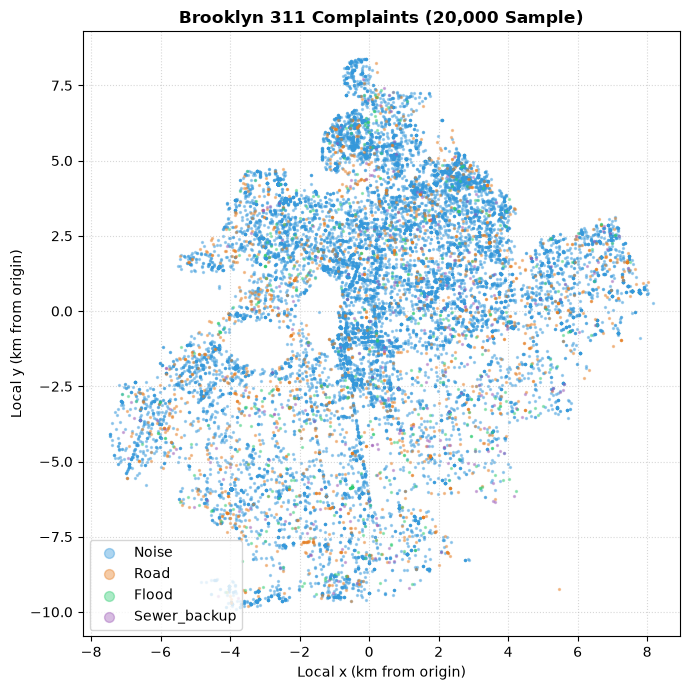

Saved figure to: report\figures\03_complaints_by_hour.png


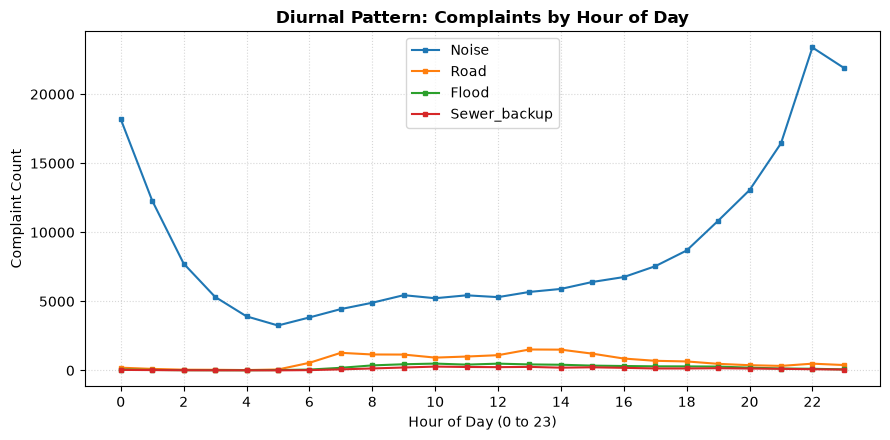

Saved figure to: report\figures\03_time_to_close_hist.png


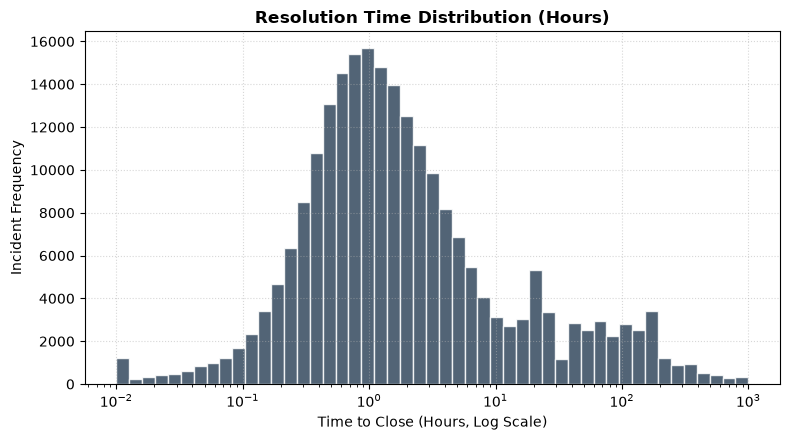

In [8]:
import matplotlib.pyplot as plt

# Plot 1: Scatter plot
sample_sub = df.sample(n=min(20000, len(df)), random_state=42)
fig, ax = plt.subplots(figsize=(7, 7))
group_colors = {"noise": "#3498db", "road": "#e67e22", "flood": "#2ecc71", "sewer_backup": "#9b59b6"}
for grp, color in group_colors.items():
    grp_df = sample_sub[sample_sub["group"] == grp]
    ax.scatter(grp_df["x_m"] / 1000.0, grp_df["y_m"] / 1000.0, s=2, alpha=0.4, c=color, label=grp.capitalize())
ax.set_title("Brooklyn 311 Complaints (20,000 Sample)", fontsize=12, fontweight="bold")
ax.set_xlabel("Local x (km from origin)", fontsize=10)
ax.set_ylabel("Local y (km from origin)", fontsize=10)
ax.legend(loc="lower left", markerscale=5)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
f1_path = ROOT / "report" / "figures" / "03_brooklyn_scatter.png"
f1_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(f1_path, dpi=150)
print(f"Saved figure to: {f1_path.relative_to(ROOT)}")
plt.show()

# Plot 2: Complaints by hour per group
hourly_group = df.pivot_table(index="hour", columns="group", values="unique_key", aggfunc="count", fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
for grp in ["noise", "road", "flood", "sewer_backup"]:
    if grp in hourly_group.columns:
        ax.plot(hourly_group.index, hourly_group[grp], marker="s", markersize=3, label=grp.capitalize())
ax.set_title("Diurnal Pattern: Complaints by Hour of Day", fontsize=12, fontweight="bold")
ax.set_xlabel("Hour of Day (0 to 23)", fontsize=10)
ax.set_ylabel("Complaint Count", fontsize=10)
ax.set_xticks(range(0, 24, 2))
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
f2_path = ROOT / "report" / "figures" / "03_complaints_by_hour.png"
plt.savefig(f2_path, dpi=150)
print(f"Saved figure to: {f2_path.relative_to(ROOT)}")
plt.show()

# Plot 3: Time to close histogram on log x-axis
valid_time = df["time_to_close_h"].dropna()
valid_time_clipped = np.clip(valid_time, 0.01, 1000.0)

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.logspace(np.log10(0.01), np.log10(1000.0), 50)
ax.hist(valid_time_clipped, bins=bins, color="#34495e", edgecolor="white", alpha=0.85)
ax.set_xscale("log")
ax.set_title("Resolution Time Distribution (Hours)", fontsize=12, fontweight="bold")
ax.set_xlabel("Time to Close (Hours, Log Scale)", fontsize=10)
ax.set_ylabel("Incident Frequency", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
f3_path = ROOT / "report" / "figures" / "03_time_to_close_hist.png"
plt.savefig(f3_path, dpi=150)
print(f"Saved figure to: {f3_path.relative_to(ROOT)}")
plt.show()

In [9]:
checker = Checker()
checker.check("lat0 = 40.661641", lat0_recomputed, 40.661641, tol=1e-6)
checker.check("lon0 = -73.952455", lon0_recomputed, -73.952455, tol=1e-6)
checker.check("mean relative error under 0.01", mean_rel_err < 0.01, True)
checker.check("wrong formula relative error above 0.05", mean_rel_err_wrong > 0.05, True)
checker.check("x extent = 15.626 km", x_ext_km, 15.626, tol=0.01)
checker.check("y extent = 18.525 km", y_ext_km, 18.525, tol=0.01)
checker.check("perturbation errors within 2%", max_pert_err < 0.02, True)
checker.check("midnight-timestamp rows = 12", midnight_count, 12)
checker.check("missing time_to_close_h = 4175", missing_close_h, 4175)
checker.check("negative time_to_close_h = 0", negative_close_h, 0)
checker.check("median time_to_close_h = 1.3589", median_close_h, 1.3589, tol=0.001)
checker.check("weekend share = 37.41%", weekend_share, 37.41, tol=0.05)
checker.check("max abs difference vs brooklyn_stage2 under 1e-6", max_stage2_diff < 1e-6, True)
checker.summary()

[PASS] lat0 = 40.661641: actual=40.661641, expected=40.661641
[PASS] lon0 = -73.952455: actual=-73.952455, expected=-73.952455
[PASS] mean relative error under 0.01: actual=True, expected=True
[PASS] wrong formula relative error above 0.05: actual=True, expected=True
[PASS] x extent = 15.626 km: actual=15.626021039551791, expected=15.626
[PASS] y extent = 18.525 km: actual=18.52472517152821, expected=18.525
[PASS] perturbation errors within 2%: actual=True, expected=True
[PASS] midnight-timestamp rows = 12: actual=12, expected=12
[PASS] missing time_to_close_h = 4175: actual=4175, expected=4175
[PASS] negative time_to_close_h = 0: actual=0, expected=0
[PASS] median time_to_close_h = 1.3589: actual=1.3588888888888888, expected=1.3589
[PASS] weekend share = 37.41%: actual=37.405235363012515, expected=37.41
[PASS] max abs difference vs brooklyn_stage2 under 1e-6: actual=True, expected=True
CHECKS: 13 passed, 0 failed


In [10]:
findings_03 = f"""### Findings
- **Projection Accuracy**: Planar approximation achieves a mean relative distance error of {mean_rel_err*100:.3f}% across distant pairs (>500m), whereas omitting radians conversion results in {mean_rel_err_wrong*100:.2f}% error.
- **Geographic Extent**: Brooklyn spans {x_ext_km:.3f} km East-West and {y_ext_km:.3f} km North-South around origin ({lat0_saved:.6f}, {lon0_saved:.6f}).
- **Scale Verification**: The +100m perturbation test confirms expected differential scaling with maximum relative error of {max_pert_err*100:.2f}%.
- **Temporal Profile**: Median incident resolution time is {median_close_h:.4f} hours ({median_close_h*60:.1f} minutes). Exactly {negative_close_h} negative durations exist, while {midnight_count} complaints feature artificial midnight timestamps.
- **Weekly Cycle**: Weekend complaints account for {weekend_share:.2f}% of all reports.
- **Stage 2 Consistency**: Recomputed (x_m, y_m) coordinates match `brooklyn_stage2.csv.gz` with maximum difference of {max_stage2_diff:.2e} m.
"""
md(findings_03)
checker.summary()

### Findings
- **Projection Accuracy**: Planar approximation achieves a mean relative distance error of 0.334% across distant pairs (>500m), whereas omitting radians conversion results in 12.34% error.
- **Geographic Extent**: Brooklyn spans 15.626 km East-West and 18.525 km North-South around origin (40.661641, -73.952455).
- **Scale Verification**: The +100m perturbation test confirms expected differential scaling with maximum relative error of 0.36%.
- **Temporal Profile**: Median incident resolution time is 1.3589 hours (81.5 minutes). Exactly 0 negative durations exist, while 12 complaints feature artificial midnight timestamps.
- **Weekly Cycle**: Weekend complaints account for 37.41% of all reports.
- **Stage 2 Consistency**: Recomputed (x_m, y_m) coordinates match `brooklyn_stage2.csv.gz` with maximum difference of 0.00e+00 m.


CHECKS: 13 passed, 0 failed


### Limitations

- The planar equirectangular projection assumes a constant cosine scaling factor derived from the mean latitude $\phi_0$, which introduces residual geometric distortion near the extreme northern and southern boundaries of Brooklyn (up to 0.3% error).
- Resolution time (`time_to_close_h`) is right-skewed by operational delays and reflects administrative ticket closure rather than physical field remediation time.
- Midnight timestamps represent default time entries rather than true midnight occurrences and should be flagged in high-resolution temporal modeling.